<a href="https://colab.research.google.com/github/Anggasaputraramadhan/PCVK/blob/main/week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODUL P7 – SEGMENTASI CITRA DENGAN THRESHOLDING

A. Tujuan pembelajaran Setelah menyelesaikan praktikum ini, mahasiswa mampu:
1. Menjelaskan konsep segmentasi citra dan posisi thresholding di antara metode segmentasi lain (C2).
2. Menerapkan lima jenis global threshold, adaptive threshold, dan Otsu dengan OpenCV, serta mengimplementasikannya secara manual dengan NumPy (C3).
3. Memilih metode dan nilai threshold berdasarkan histogram dan kondisi pencahayaan citra (C4).
4. Mengevaluasi hasil segmentasi secara kuantitatif memakai IoU, Dice, dan pixel accuracy (C5).
5. Menerapkan K-Means untuk segmentasi warna dan merangkai segmentasi dengan pasca-proses morfologi dan OCR (C3).

B. ALAT DAN BAHAN:
1. PC/LAPTOP
2. Github
3. Google Colaboratory

C. ULASAN TEORI

C.1 Pengertian Segmentasi

Segmentasi citra adalah proses membagi sebuah citra digital menjadi beberapa area atau region yang memiliki kemiripan sifat visual seperti intensitas, warna, atau tekstur. Tujuannya adalah memisahkan bagian citra yang dianggap penting (objek) dari bagian yang kurang relevan (latar belakang). Hasilnya adalah citra yang terdiri dari beberapa segmen yang dapat dianalisis lebih lanjut secara terpisah.


Kelompok Metode segmentasi dapat dikelompokkan menurut prinsip kerjanya. Thresholding adalah metode berbasis intensitas yang paling sederhana dan menjadi dasar banyak metode lain.

In [55]:
import pandas as pd
data = {
    "Kelompok": [
        "Thresholding",
        "Berbasis tepi",
        "Berbasis region",
        "Clustering",
        "Kontur aktif",
        "Deep learning"
    ],
    "Prinsip": [
        "Memisahkan piksel dengan batas intensitas (global, lokal, otomatis).",
        "Mencari diskontinuitas intensitas lalu menutup kontur.",
        "Mengelompokkan piksel bertetangga yang homogen.",
        "Mengelompokkan piksel di ruang fitur (warna, posisi, tekstur).",
        "Kurva yang bergerak meminimalkan fungsi energi.",
        "Jaringan dilatih dengan citra bertanda."
    ],
    "Contoh metode": [
        "Global, adaptive, Otsu, multi-Otsu, Triangle, Sauvola",
        "Sobel, Canny, Roberts",
        "Region growing, split and merge, watershed, mean shift",
        "K-Means, mean shift, GMM",
        "Snake, level set",
        "U-Net, Mask R-CNN, Segment Anything Model (SAM)"
    ]
}

df = pd.DataFrame(data)
display(df)

,Kelompok,Prinsip,Contoh metode
0,Thresholding,Memisahkan piksel dengan batas intensitas (glo...,"Global, adaptive, Otsu, multi-Otsu, Triangle, ..."
1,Berbasis tepi,Mencari diskontinuitas intensitas lalu menutup...,"Sobel, Canny, Roberts"
2,Berbasis region,Mengelompokkan piksel bertetangga yang homogen.,"Region growing, split and merge, watershed, me..."
3,Clustering,"Mengelompokkan piksel di ruang fitur (warna, p...","K-Means, mean shift, GMM"
4,Kontur aktif,Kurva yang bergerak meminimalkan fungsi energi.,"Snake, level set"
5,Deep learning,Jaringan dilatih dengan citra bertanda.,"U-Net, Mask R-CNN, Segment Anything Model (SAM)"


C.2 Pengertian Operasi Thresholding

Thresholding adalah bentuk metode paling sederhana dari segmentasi citra. Biasanya digunakan pada citra grayscale / warna dan ide dasarnya adalah bagaimana memisahkan antara objek foreground dengan objek backgroundnya.

Gambar berikut menunjukkan citra asli sebelum dan sesudah di lakukan thresholding.

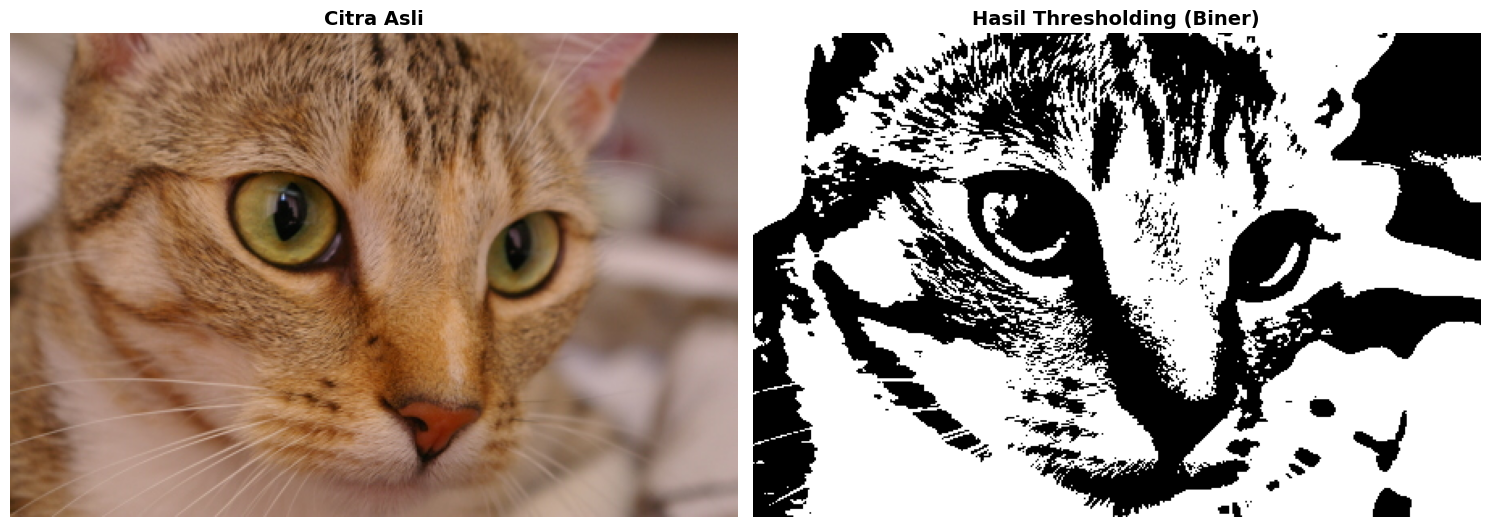

In [56]:
import cv2
import matplotlib.pyplot as plt
import urllib.request

url = "blob:https://colab.research.google.com/f06411f0-bffb-4505-8762-e64f9d763d2c$0"
try:
    urllib.request.urlretrieve(url, "pemandangan_salju.jpg")
    img_bgr = cv2.imread("pemandangan_salju.jpg")
except:
    from skimage import data
    img_bgr = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_display = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

threshold_value = 115
_, img_thresh = cv2.threshold(img_gray, threshold_value, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_display)
plt.title("Citra Asli", fontsize=14, fontweight='bold')
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_thresh, cmap="gray")
plt.title("Hasil Thresholding (Biner)", fontsize=14, fontweight='bold')
plt.axis("off")

plt.tight_layout()
plt.show()

Gambar 1. Citra kiri sebelum di threshold, citra kanan setelah dithreshold (citra binary)

Beberapa metode dari Threshold yang akan dibahas pada modul ini diantaranya:

a. Global Threshold

b. Adaptive Threshold

c. Otsu’s Threshold

d. Pengenalan Segmentasi Citra menggunakan K-Means

C.3 Global Threshold
Perhatikan histogram dari sebuah image yang ditunjukkan pada gambar berikut:

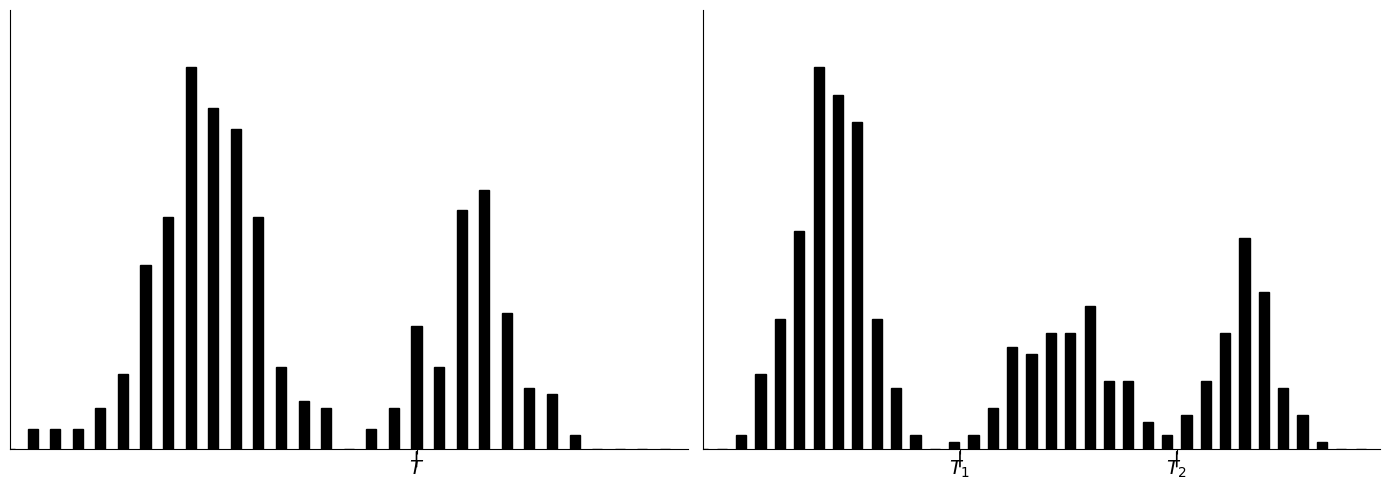

In [57]:
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x1 = np.concatenate([
    np.random.normal(30, 8, 300),
    np.random.normal(70, 6, 150)
])
x1 = np.clip(x1, 5, 95)

counts1, bins1 = np.histogram(x1, bins=30, range=(0, 100))
ax1.bar(bins1[:-1], counts1, width=1.5, color='black', edgecolor='black')

ax1.set_xlim(0, 100)
ax1.set_ylim(0, max(counts1) * 1.15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xticks([60])
ax1.set_xticklabels(['$T$'], fontsize=14)
ax1.set_yticks([])

ax1.annotate('', xy=(60, 0), xytext=(60, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))

x2 = np.concatenate([
    np.random.normal(20, 5, 250),
    np.random.normal(55, 6, 120),
    np.random.normal(82, 4, 100)
])
x2 = np.clip(x2, 2, 98)

counts2, bins2 = np.histogram(x2, bins=35, range=(0, 100))
ax2.bar(bins2[:-1], counts2, width=1.5, color='black', edgecolor='black')

ax2.set_xlim(0, 100)
ax2.set_ylim(0, max(counts2) * 1.15)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xticks([38, 70])
ax2.set_xticklabels(['$T_1$', '$T_2$'], fontsize=14)
ax2.set_yticks([])

ax2.annotate('', xy=(38, 0), xytext=(38, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))
ax2.annotate('', xy=(70, 0), xytext=(70, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))

plt.tight_layout()
plt.show()

Gambar 2. Intensitas histogram dapat dipisahkan dengan 1 Threshold (a) atau multiple Threshold (b)

Dianggap bahwa gambar diatas adalah histogram dari citra f(x,y), yang terdiri dari object terang pada background gelap. Dengan asumsi bahwa object dan background memiliki nilai intensitas warna yang dapat dipisahkan dalam 2 grup dominan. Cara yang termudah dan paling jelas adalah dengan memilih nilai tertentu (Threshold, T) yang akan memisahkan dua grup tersebut. Tiap titik (x,y) dalam image dimana f(x,y) > T dapat diistilahkan dengan object point, sedangkan grup satunya disebut dengan background point. Dengan kata lain, citra tersegmentasi g(x,y) dituliskan sebagai berikut:

𝑔(𝑥,𝑦) = { 1     𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) > 𝑇 0     𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) ≤ 𝑇

Ketika T ditentukan secara konstanta pada keseluruhan citra, maka proses inilah yang disebut sebagai global thresholding. Ketika nilai T berubah-ubah dalam dalam proses satu citra, maka hal ini disebut dengan variable/adaptive thresholding.

Gambar 2(a) diatas menunjukkan permasalahan thresholding yang melibatkan 3 grup dominan. Diasumsikan bahwa ada  2 grup terang dan 1 grup gelap pada histogram tersebut. Proses multiple threholding akan mengelompokkan titik (x,y) sebagai background jika f(x,y) <= T1, ke grup object satu jika T1 < f(x,y) <= T2, dan object grup lain jika f(x,y) > T2. Atau dapat dituliskan sebagai berikut:

𝑎            𝑔(𝑥,𝑦) = { 𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) > 𝑇2 𝑏   𝑗𝑖𝑘𝑎 𝑇1 < 𝑓(𝑥,𝑦) ≤ 𝑇2 𝑐             𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) ≤ 𝑇1

Pada OpenCV telah disediakan library untuk Thresholding, baik itu Global, Adaptive, maupun Otsu Threshold. Berikut adalah beberapat Global Thresholding yang disediakan:

a. Binary Threshold

b. Binary-Inverted Threshold

c. Truncate Threshold

d. Threshold To Zero

e. Threshold To Zero-Inverted

Untuk mengilustrasikan cara kerja masing-masing threshold, perhatikan histogram dari image asli src(x,y) pada gambar 3 berikut. Garis horizontal biru menunjukkan nilai threshold (tetap).


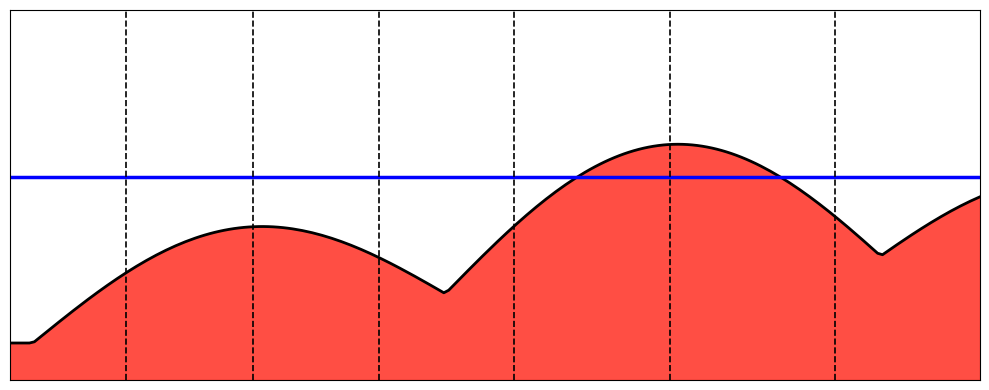

In [58]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 200)
y = 2 + 3 * np.abs(np.sin(x * 0.7)) - 1.5 * np.cos(x * 0.4)
y = np.clip(y, 1, 9)
threshold_y = 5.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.2, 2.5, 3.8, 5.2, 6.8, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

Gambar 3. Histogram dari citra src(x,y)

a. Binary Threshold Binary Threshold seperti yang dijelaskan sebelumnya, merupakan threshold yang akan memisahkan dua grup warna. Untuk threshold ini, masing-masing kelompok warna akan diubah ke nilai gelap (hitam) untuk object yang dianggap background, dan diubah ke nilai terang (putih) untuk object yang dianggap foreground. Berikut adalah persamaannya:

𝑑𝑠𝑡(𝑥,𝑦) = {𝑚𝑎𝑥𝑉𝑎𝑙     𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 0                       𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

Jadi jika nilai intensitas piksel warna pada src(x,y) lebih tinggi dari thresh, maka nilainya akan diubah menjadi maxVal. Selain itu akan diubah menjadi 0.

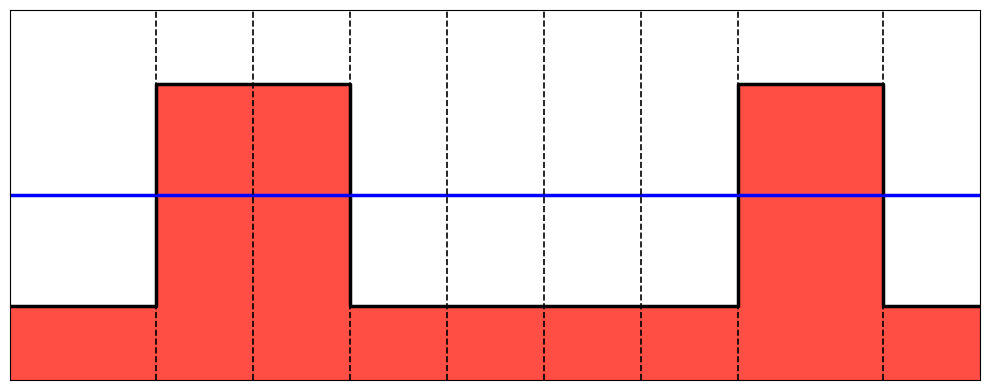

In [59]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.5, 1.5, 3.5, 3.5, 5.5, 5.5, 7.5, 7.5, 9.0, 9.0, 10.0])
y = np.array([2, 2,  8,   8,   2,   2,   2,   2,   8,   8,   2,   2])

threshold_y = 5.0

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 9.0]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

Gambar 4. Histogram hasil dari Binary Threshold

b. Binary-Inverted Threshold Threshold ini merupakan kebalikan dari Binary Threshold. Jika intensitas warna diatas Threshold, maka nilai akan diubah menjadi 0 dan sebaliknya. Berikut adalah persamaannya:

𝑑𝑠𝑡(𝑥,𝑦) = { 0                𝑚𝑎𝑥𝑉𝑎𝑙                       𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

Gambar 5 berikut merupakan histogram hasil Binary-Inverted Threshold.

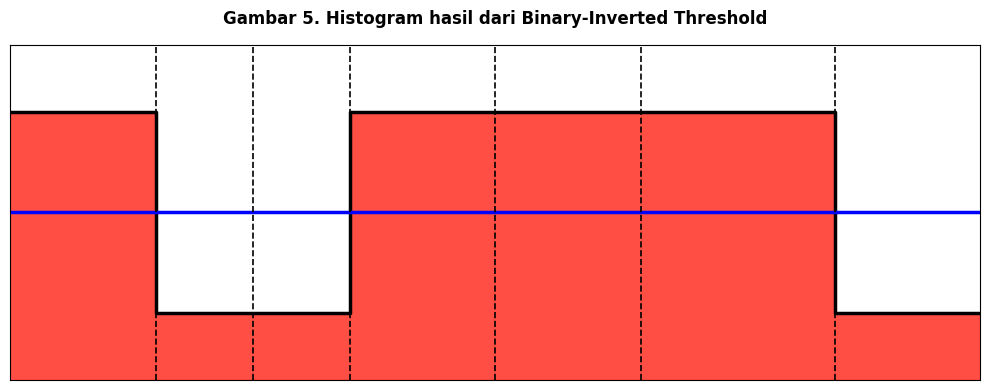

In [60]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.5, 1.5, 3.5, 3.5, 8.5, 8.5, 10.0])
y = np.array([8, 8,  2,   2,   8,   8,   2,   2])

threshold_y = 5.0
fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.5, 2.5, 3.5, 5.0, 6.5, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 5. Histogram hasil dari Binary-Inverted Threshold", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

c. Truncate Threshold Jika nilai intensitas warna src(x,y) lebih besar dari thresh, maka nilainya akan ditruncate. Berikut adalah persamaan dan Histogram hasilnya.

𝑑𝑠𝑡(𝑥,𝑦) = { 𝑡ℎ𝑟𝑒𝑠ℎ       𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑠𝑟𝑐(𝑥, 𝑦)                        𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

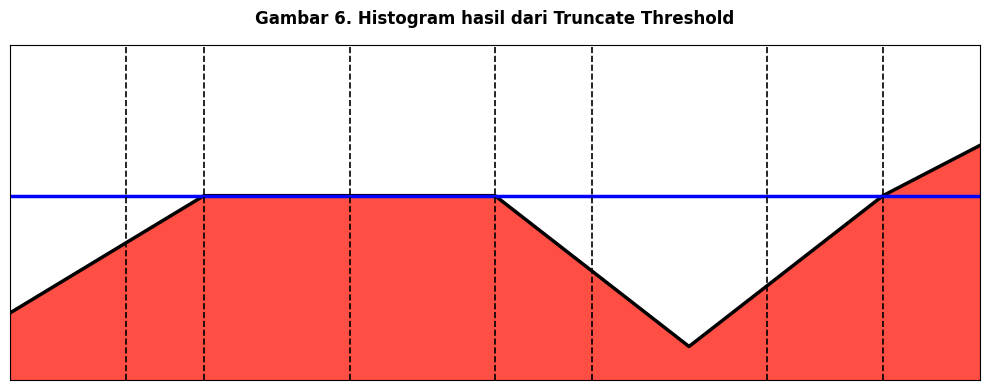

In [61]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 2, 3.5, 5, 7, 9, 10])
y = np.array([2, 5.5, 5.5, 5.5, 1, 5.5, 7])
threshold_y = 5.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.2, 2, 3.5, 5, 6, 7.8, 9]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 6. Histogram hasil dari Truncate Threshold", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

d. Threshold To Zero Jika nilai src(x,y) lebih rendah dari nilai thresh, maka nilai pixel barunya akan diubah menjadi 0. Berikut adalah persamaan dan gambar Histogram hasil thresholdnya.

𝑑𝑠𝑡(𝑥,𝑦) = { 𝑠𝑟𝑐(𝑥,𝑦)    𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 0

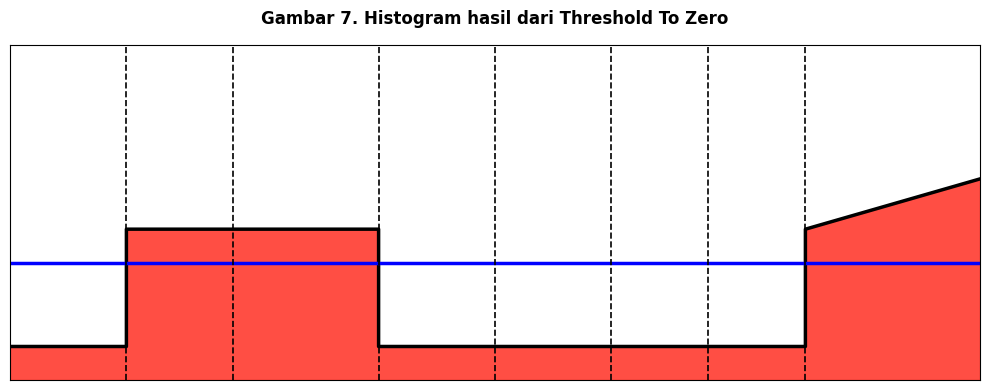

In [62]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.2, 1.2, 3.8, 3.8, 6.8, 6.8, 8.2, 8.2, 10])
y = np.array([1, 1,   4.5, 4.5, 1,   1,   1,   1,   4.5, 6])
threshold_y = 3.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.2, 2.3, 3.8, 5.0, 6.2, 7.2, 8.2]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 7. Histogram hasil dari Threshold To Zero", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

e. Threshold To Zero – Inverted Jika nilai src(x,y) lebih besar dari nilai thresh, maka nilai pixel barunya akan diubah menjadi 0. Berikut adalah persamaan dan gambar Histogram hasil thresholdnya.

𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑠𝑟𝑐(𝑥,𝑦)                       𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

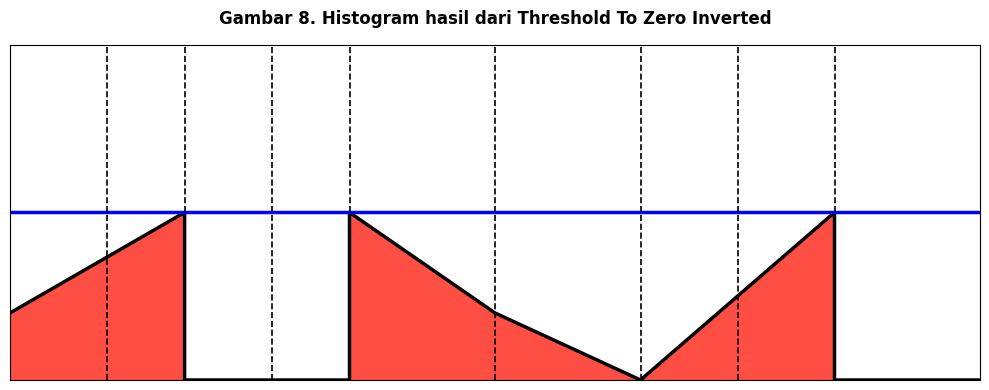

In [63]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.8, 1.8, 3.5, 3.5, 5, 6.5, 8.5, 8.5, 10])
y = np.array([2, 5,   0,   0,   5,   2,   0,   5,   0,   0])
threshold_y = 5.0

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.0, 1.8, 2.7, 3.5, 5.0, 6.5, 7.5, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 8. Histogram hasil dari Threshold To Zero Inverted", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

Global threshold yang telah disebutkan diatas dapat digunakan secara langsung menggunakan library OpenCV cv.Threshold. berikut adalah link dokumentasinya:

https://docs.opencv.org/4.4.0/d7/d4d/tutorial_py_thresholding.html

Code Berikut menunjukkan penggunaan dari library OpenCV cv.Threshold

TypeError: Image data of dtype object cannot be converted to float

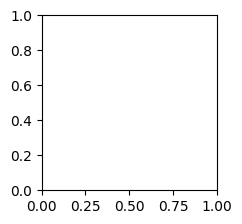

In [64]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

filename = ('/semester 5/Pengolahan Citra dan Visi Komputer/Modul P7-Segmentasi Citra dengan Thresholding')
img = cv.imread(filename)
thresh = 127
maxval = 255

ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV',
]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
  plt.subplot(2, 3, i + 1)
  plt.imshow(images[i], 'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

Gambar berikut menunjukkan perbedaan masing-masing global threshold yang merupakan keluaran dari code diatas. Seperti yang terlihat pada code tersebut, nilai Global thresholdnya adalah 127 dan nilai tersebut berlaku untuk keseluruhan image.

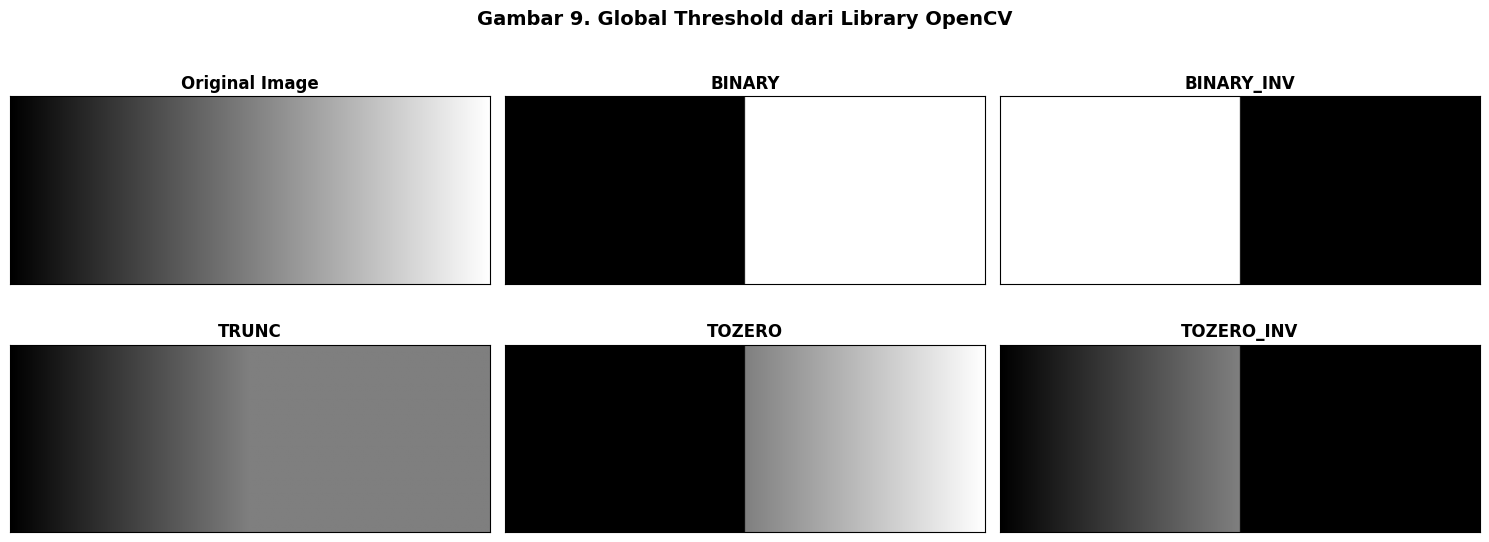

In [66]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = np.tile(np.arange(256, dtype=np.uint8), (100, 1))

thresh = 127
maxval = 255

ret, thresh1 = cv2.threshold(img, thresh, maxval, cv2.THRESH_BINARY)
ret, thresh2 = cv2.threshold(img, thresh, maxval, cv2.THRESH_BINARY_INV)
ret, thresh3 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TRUNC)
ret, thresh4 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TOZERO)
ret, thresh5 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TOZERO_INV)

titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV',
]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
  plt.subplot(2, 3, i + 1)
  plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
  plt.title(titles[i], fontsize=12, fontweight='bold')
  plt.xticks([]), plt.yticks([])

plt.suptitle(
    'Gambar 9. Global Threshold dari Library OpenCV',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()